**About:** Cell Tracking — TemporalUNet3D + SimpleNodeTransformer Inference

In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
cd ../src

/data/kaggle-cell-tracking/src


In [5]:
import os
import cv2
import glob
import json
import torch
import zarr
import shutil
import warnings
import polars as pl
import numpy as np
import pandas as pd
import tracksdata as td
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from pathlib import Path
from collections import Counter

warnings.filterwarnings("ignore", category=UserWarning)

In [6]:
from tracking_cellmot.io import save_graph
from tracking.plot import plot_detection, plot_edges, plot_sample
from utils.plot import plot_contours, scatter_plot_center_preds

from utils.metrics import match_frame_nodes
from tracking.post_process import build_graph
from tracking_cellmot.metrics import evaluate, node_recall, per_sample_metrics, summarise

from tracking.predict import predict_video

from utils.logger import Config
from tracking.main import build_model

In [7]:
from params import TRAIN_DIR, LOG_FOLDER, SCALE

TRAIN_DIR = Path(TRAIN_DIR)
LOG_FOLDER = Path(LOG_FOLDER)

WINDOW_SIZE = 2

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

Device: cuda


### Model

In [27]:
LOG_FOLDER = "../logs/2026-08-18/35/"  # new seg
LOG_FOLDER = "../logs/2026-08-19/2/"  # full res seg + frozen unet
LOG_FOLDER = "../logs/2026-08-19/5/"  # full res seg + frozen unet + geom fts
LOG_FOLDER = "../logs/2026-08-19/14/"  # full res seg + geom fts only
LOG_FOLDER = "../logs/2026-08-20/0/"  # full res seg + geom fts only + PL

LOG_FOLDER = "../logs/2026-08-20/3/"  # full res seg + geom fts only + PL
# LOG_FOLDER = "../logs/2026-08-20/4/"  # full res seg + geom fts only + PL
LOG_FOLDER = "../logs/2026-08-20/20/"  # full res seg + geom fts adjust + PL
LOG_FOLDER = "../logs/2026-08-26/4/"  # more pL

LOG_FOLDER = "../logs/2026-08-28/13/"
LOG_FOLDER = "../logs/2026-08-28/19/"  # PL 13

LOG_FOLDER = "../logs/2026-08-31/33/"  # Synthetic Pre - BEST

LOG_FOLDER = "../logs/2026-08-31/40/"  # Synthetic Pre + PL - BEST

FOLD = 0

In [28]:
cfg = Config(json.load(open(LOG_FOLDER + "args.json", "r")))
exp_name = "_".join(LOG_FOLDER[:-1].split('/')[-2:])

In [29]:
checkpoints = sorted(glob.glob(LOG_FOLDER + f"fold_{FOLD}/ckpt_*.pt", recursive=True))

print("\n".join(checkpoints))

# ckpt_name = "ckpt_stage_seg_02000.pt"
ckpt_name = "ckpt_final.pt"

try:
    ckpt_name = "ckpt_final.pt"
    ckpt_path = LOG_FOLDER + f"fold_{FOLD}/" + ckpt_name
    assert os.path.exists(ckpt_path)
except:
    ckpt_name = "ckpt_pretrain.pt"
    ckpt_path = LOG_FOLDER + f"fold_{FOLD}/" + ckpt_name
    assert os.path.exists(ckpt_path)

print('\n-> Loading checkpoint: ', ckpt_path)

../logs/2026-08-31/40/fold_0/ckpt_final.pt
../logs/2026-08-31/40/fold_0/ckpt_pretrain.pt
../logs/2026-08-31/40/fold_0/ckpt_stage_seg_00500.pt
../logs/2026-08-31/40/fold_0/ckpt_stage_seg_01000.pt
../logs/2026-08-31/40/fold_0/ckpt_synthetic.pt

-> Loading checkpoint:  ../logs/2026-08-31/40/fold_0/ckpt_final.pt


In [30]:
model = build_model(cfg, None)
model.eval().to(device)

ckpt = torch.load(ckpt_path)
state = ckpt.get("model_state_dict", ckpt)
model.load_state_dict(state, strict=True)

<All keys matched successfully>

### Data

In [32]:
HARD_FOLD_0 = [
    "44b6_2f31fc2f", # 0.51
    "44b6_a2bb48bb", # 0.58
]

HARD_FOLD_1 = [
    "6bba_6feb10f0", # 0.25
    "6bba_ab78413d", # 0.41
    "6bba_c73a1d11", # 0.47
    "6bba_474be664", # 0.55
    "6bba_ebff6e76", # 0.56
    "6bba_57b7cc1e", # 0.57
    "6bba_207c6aaf", # 0.57
    "6bba_3db54e20", # 0.58
]

In [33]:
sample_name = "44b6_a2bb48bb"

In [34]:
df = pd.read_csv(f"../input/metadata.csv")
n_total = df[df['sample_name'] == sample_name]["estimated_number_of_nodes"].values[0]
print(f"Estimated number of nodes: {n_total}")

Estimated number of nodes: 60613


In [35]:
tracks_path = TRAIN_DIR / f"{sample_name}.geff"
result = td.graph.IndexedRXGraph.from_geff(tracks_path)
gt_graph = result[0] if isinstance(result, tuple) else result

node_attrs = gt_graph.node_attrs()

In [36]:
vol = zarr.open_group(str(TRAIN_DIR / f'{sample_name}.zarr'), mode="r")["0"]

### Predict

In [37]:
class PredictConfig:
    det_tta = False

    # --- Nodes ---
    nms = "greedy"
    nms_radius_um = 7.0
    det_threshold = 0.5
    pool_kernel_um = 5.0
    edge_activation = "softmax"

    # --- Edges ---
    edge_selection = "argmax"
    edge_threshold = 0.
    
    max_parents_per_node = 1
    max_children_per_node = 2

In [38]:
coords, edges, det_logits = predict_video(
    model,
    TRAIN_DIR / sample_name,
    device=device,
    cfg=PredictConfig,
    window_size=WINDOW_SIZE,
    max_frames=100,
)

# coords: (N, 4) [t, z, y, x] in ORIGINAL resolution
# edges:  list of (src_idx, tgt_idx, prob, distance) indexing rows of coords

windows:   0%|          | 0/99 [00:00<?, ?it/s]

In [39]:
# out_dir = Path(f"../output/predictions/{exp_name}")

# np.savez_compressed(
#     out_dir / f"{sample_name}.npz",
#     coords=coords,
#     edges=np.asarray(edges, dtype=np.float64).reshape(-1, 4),
# )

In [40]:
# out = np.load(f"{LOG_FOLDER}/preds_0.20/{sample_name}.npz")

In [41]:
print(f"- Found {coords.shape[0]} nodes & {len(edges)} edges")
print(f"- Estimated number of nodes: {n_total}")

- Found 63724 nodes & 63158 edges
- Estimated number of nodes: 60613


In [42]:
graph = build_graph(coords, edges)

res = evaluate(graph, gt_graph, scale=SCALE)

node_recall_ = node_recall(graph, gt_graph)
print(f"- Node recall: {node_recall_:.3f}")

metrics = per_sample_metrics(res, n_total, node_recall_)
metrics = summarise([metrics])

for k in ["edge_tp", "edge_fp", "edge_fn"]:
    print(f"- {k}: {metrics[k]:.0f}")
for k in ["edge_jaccard", "adj_edge_jaccard", "division_jaccard", "score"]:
    print(f"- {k}: {metrics[k]:.3f}")


- Node recall: 0.887
- edge_tp: 277
- edge_fp: 175
- edge_fn: 133
- edge_jaccard: 0.474
- adj_edge_jaccard: 0.471
- division_jaccard: 0.000
- score: 0.471


In [43]:
# os.makedirs(f"../output/predictions/{exp_name}", exist_ok=True)
# output_path = f"../output/predictions/{exp_name}/{sample_name}.geff"

# if os.path.exists(output_path):
#     shutil.rmtree(output_path)
# graph.to_geff(output_path)

# print(f"-> Saved graph to {output_path}")

In [44]:
# from utils.build_graph import build_graph_from_nodes

# coords_ = {t: coords[coords[:, 0] == t][:, 1:] for t in range(coords[:, 0].max() + 1)}
# graph = build_graph_from_nodes(coords_, max_distance=7.0)

# res = evaluate(graph, gt_graph, scale=SCALE)

# node_recall_ = node_recall(graph, gt_graph)
# print(f"- Node recall: {node_recall_:.3f}")

# metrics = per_sample_metrics(res, n_total, node_recall_)
# metrics = summarise([metrics])

# for k in ["edge_tp", "edge_fp", "edge_fn"]:
#     print(f"- {k}: {metrics[k]:.0f}")
# for k in ["edge_jaccard", "adj_edge_jaccard", "division_jaccard", "score"]:
#     print(f"- {k}: {metrics[k]:.3f}")


#### Plot nodes

-> Matched 5 out of 6 GT nodes at frame 0


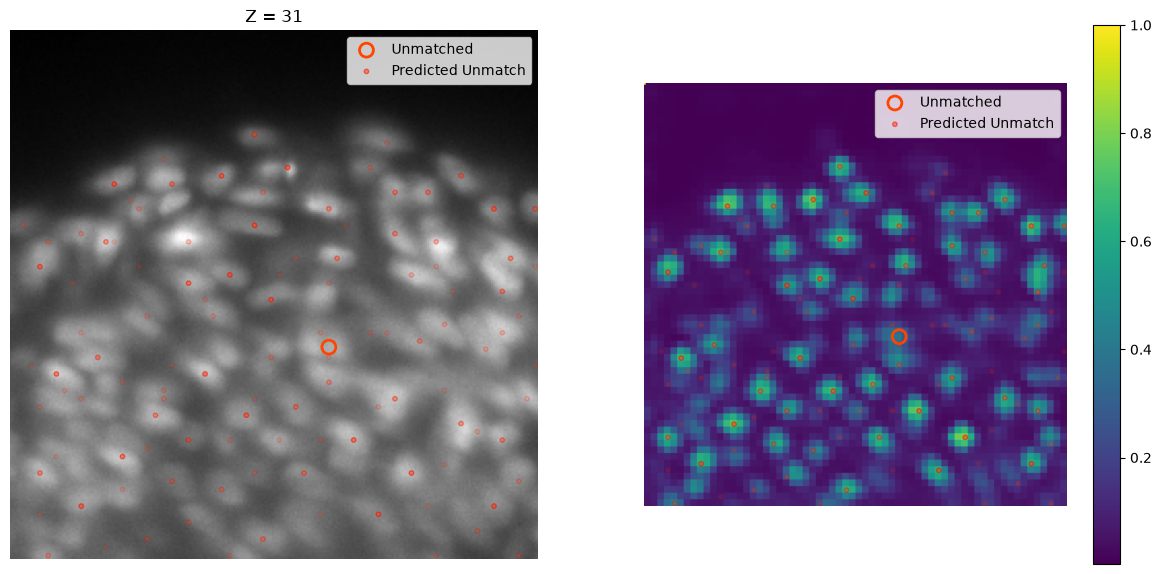

-> Matched 5 out of 6 GT nodes at frame 1


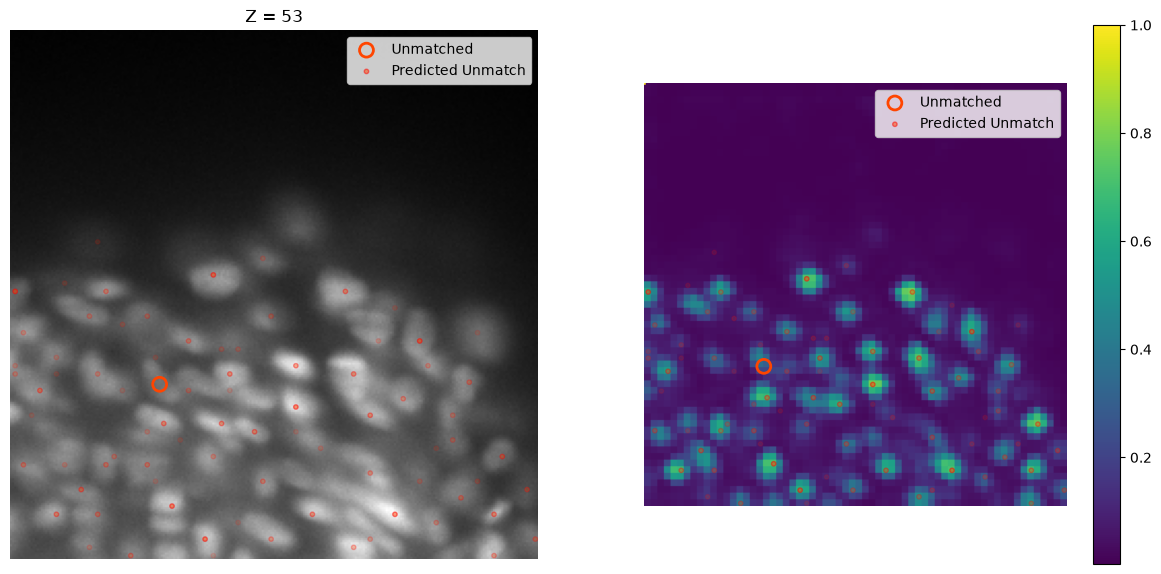

-> Matched 6 out of 6 GT nodes at frame 2
-> Matched 6 out of 6 GT nodes at frame 3
-> Matched 5 out of 6 GT nodes at frame 4


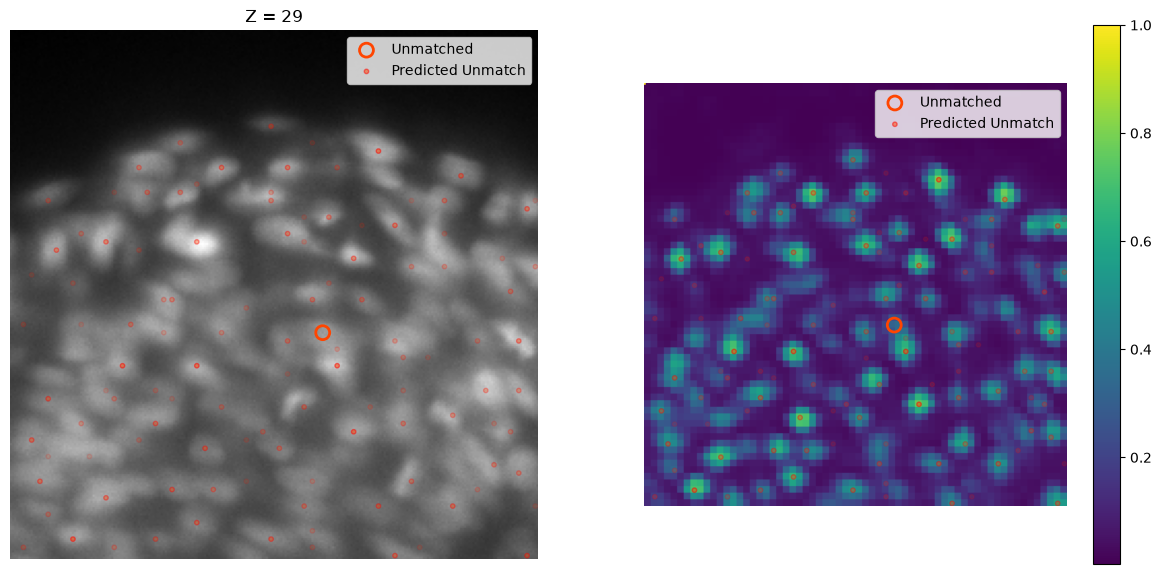

-> Matched 5 out of 6 GT nodes at frame 5


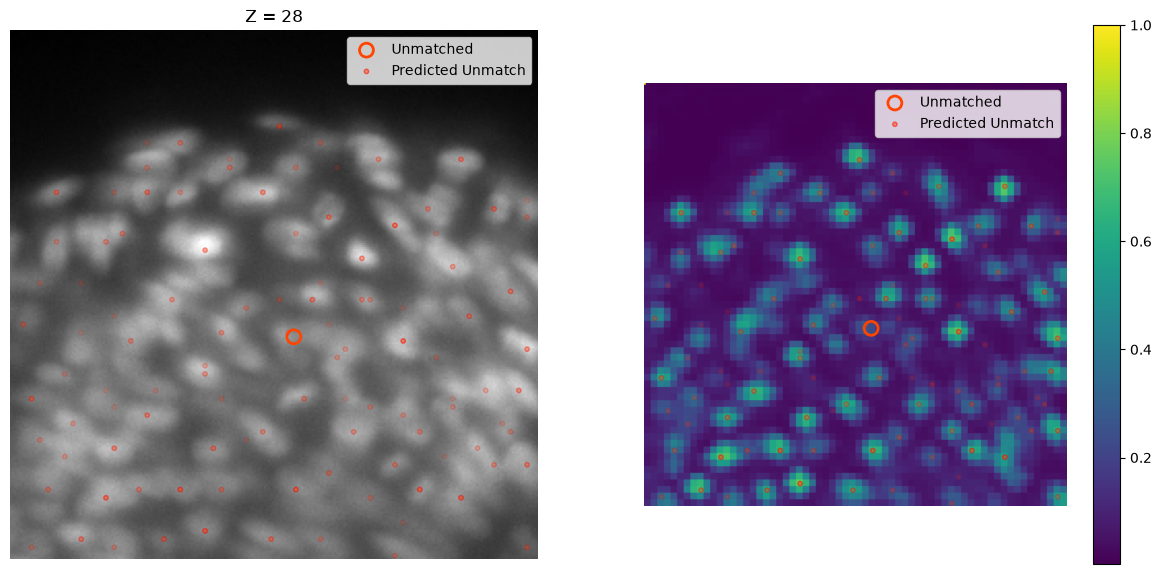

-> Matched 5 out of 6 GT nodes at frame 6


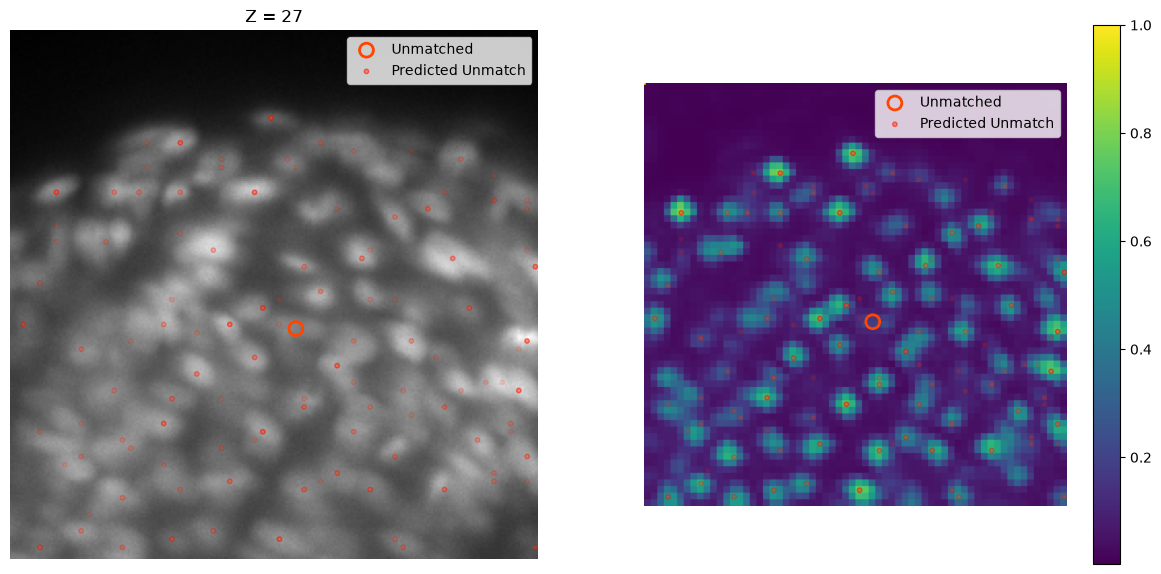

-> Matched 5 out of 6 GT nodes at frame 7


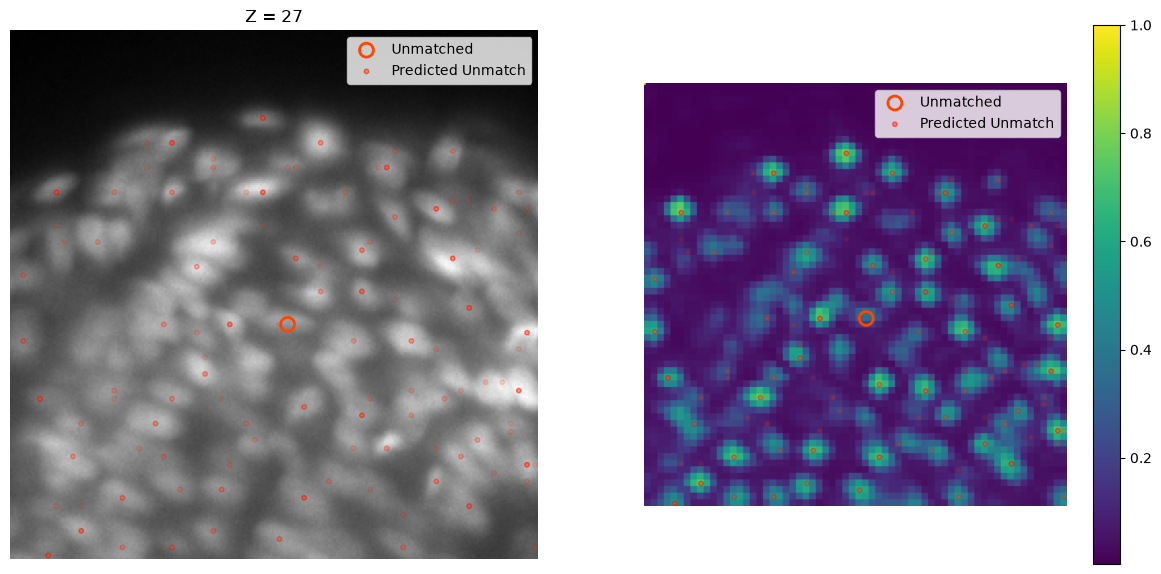

-> Matched 4 out of 4 GT nodes at frame 8
-> Matched 4 out of 4 GT nodes at frame 9
-> Matched 4 out of 4 GT nodes at frame 10
-> Matched 4 out of 4 GT nodes at frame 11
-> Matched 4 out of 4 GT nodes at frame 12
-> Matched 4 out of 4 GT nodes at frame 13
-> Matched 4 out of 4 GT nodes at frame 14
-> Matched 4 out of 4 GT nodes at frame 15
-> Matched 3 out of 4 GT nodes at frame 16


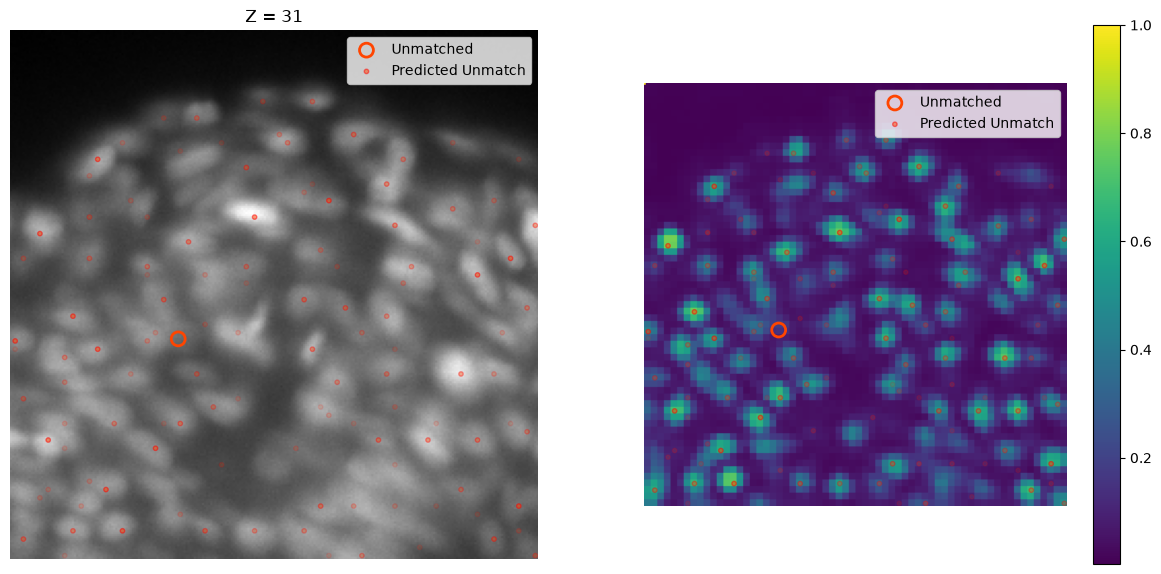

-> Matched 3 out of 4 GT nodes at frame 17


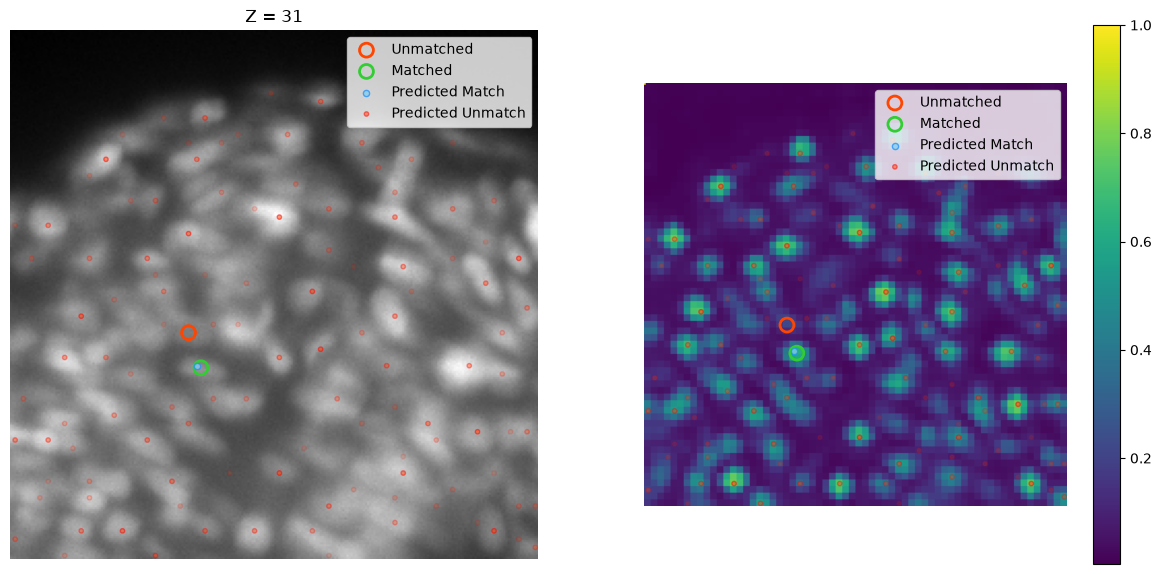

-> Matched 3 out of 4 GT nodes at frame 18


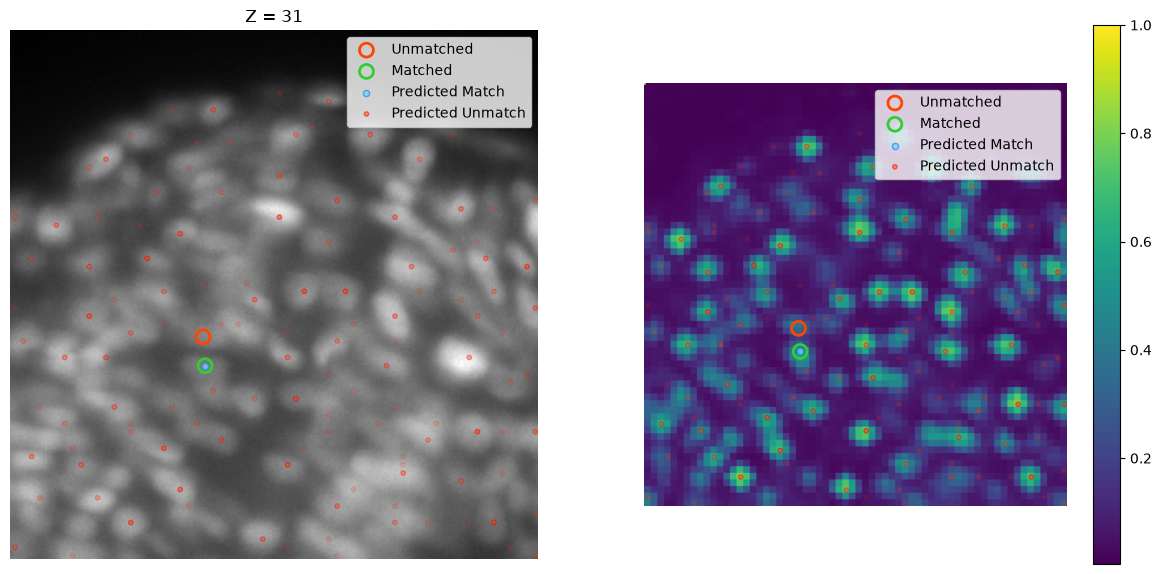

-> Matched 4 out of 4 GT nodes at frame 19
-> Matched 4 out of 4 GT nodes at frame 20
-> Matched 4 out of 4 GT nodes at frame 21
-> Matched 3 out of 4 GT nodes at frame 22


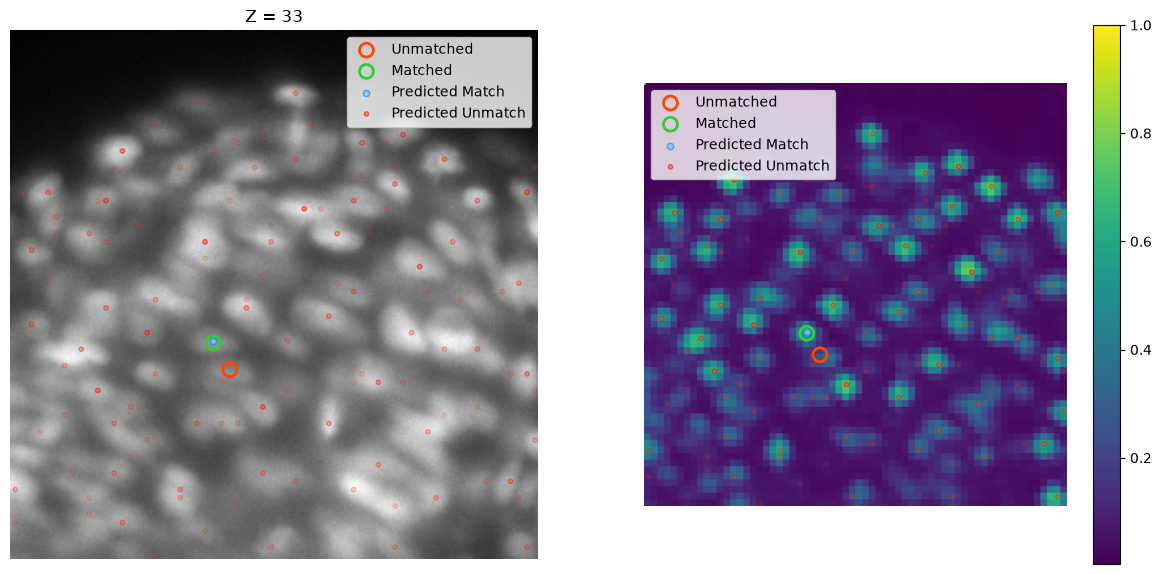

-> Matched 4 out of 4 GT nodes at frame 23
-> Matched 3 out of 4 GT nodes at frame 24


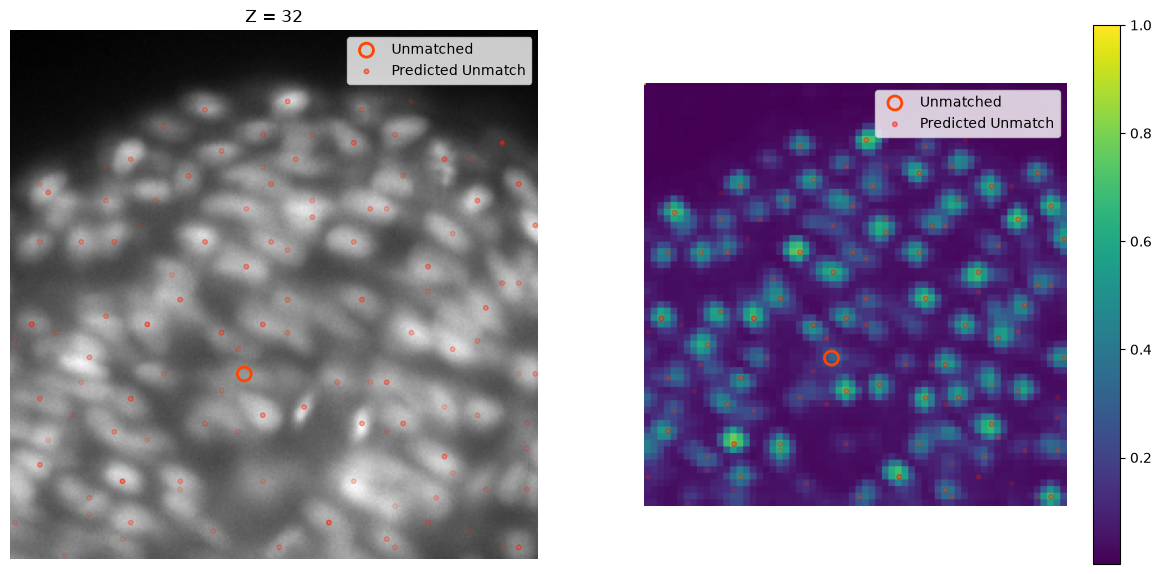

In [45]:
gt_ = node_attrs.to_pandas()

n_plot = 0

for frame in gt_["t"].unique():
    gt = gt_[gt_["t"] == frame][["z", "y", "x"]].values

    preds = coords[coords[:, 0] == frame][:, 1:]

    pairs, matched_gt, unmatched_gt = match_frame_nodes(
        preds,
        gt,
        t=frame,
        scale=SCALE,
        max_distance=7,
    )

    print(f'-> Matched {len(pairs)} out of {len(gt)} GT nodes at frame {frame}')

    img = vol[frame]
    ids = np.unique(unmatched_gt[:, 0]) if len(unmatched_gt) > 0 else []  # np.unique(gt[:, 0])

    # ids = np.concatenate([ids, ids + 1, ids - 1])
    # ids = sorted(np.unique(ids))

    if not len(ids):
        continue

    tol = 5

    for i in ids:
        for d in [0]:
            plt.figure(figsize=(15, 7))
            plt.subplot(1, 2, 1)
            plt.title(f"Z = {i + d}")
            plt.imshow(img[i + d], cmap="gray")
            plt.axis("off")
            # break
            scatter_plot_center_preds(preds, matched_gt, unmatched_gt, frame=i + d, tol=tol)
            plt.subplot(1, 2, 2)

            det_logits_ = det_logits[frame][0].squeeze()[(i + d)].sigmoid().numpy()
            det_logits_ = cv2.resize(det_logits_, (img.shape[1], img.shape[2]), interpolation=0)
            # det_logits_ = np.where(det_logits_ > PredictConfig.det_threshold, det_logits_, 0)
            det_logits_[0, 0] = 1
            plt.imshow(det_logits_)
            plt.colorbar()
            scatter_plot_center_preds(preds, matched_gt, unmatched_gt, frame=i + d, tol=tol)
            plt.axis("off")
            plt.show()
            n_plot += 1
    # break

    if n_plot > 10:
        break


In [199]:
# import tifffile

# tifffile.imwrite(
#     f"../output/{sample_name}_{frame}.tiff",
#     img,
#     photometric="minisblack",
# )

### Post-processing

In [ ]:
no_pipeline = False
no_pp_public = False
ilp = False

cfg_pp = dict(
    out_dir=LOG_FOLDER + "preds_pp/",
    geff_dir=f"../output/predictions/{exp_name}_pp",
    no_pipeline=no_pipeline,
    no_pp_public=no_pp_public,
    ilp=ilp,
    no_score=False,
    skip_existing=False,
)

In [ ]:
from main_postprocess import process

res = process((LOG_FOLDER + f"preds/{sample_name}.npz", cfg_pp))

preds_pp = np.load(LOG_FOLDER + "preds_pp/" + f"{sample_name}.npz", allow_pickle=True)

edges_pp = preds_pp['edges']
edges_pp = [(int(e[0]), int(e[1]), e[2], e[3]) for e in edges_pp]
coords_pp = preds_pp['coords']

In [ ]:
graph = build_graph(coords_pp, edges_pp)

res = evaluate(graph, gt_graph, scale=SCALE)

node_recall_ = node_recall(graph, gt_graph)
print(f"- Node recall: {node_recall_:.3f}")

metrics = per_sample_metrics(res, n_total, node_recall_)
metrics = summarise([metrics])

for k in ["edge_tp", "edge_fp", "edge_fn"]:
    print(f"- {k}: {metrics[k]:.0f}")
for k in ["edge_jaccard", "adj_edge_jaccard", "division_jaccard", "score"]:
    print(f"- {k}: {metrics[k]:.3f}")


### More PP

In [ ]:
from tracking.pp_public import postprocess_graph

In [ ]:
%%time
nodes_pp, edges_pp, filter_stats = postprocess_graph(graph_ilp, dataset=sample_name)

In [ ]:
id_mapping = {n['node_id']: i for i, n in enumerate(nodes_pp)}
nodes_pp = [[n['t'], n['z'], n['y'], n['x']] for n in nodes_pp]
nodes_pp = np.array(nodes_pp)

edges_pp_ = [(id_mapping[e['source_id']], id_mapping[e['target_id']], e['edge_prob'], e['distance_um']) for e in edges_pp]
graph_pp = build_graph(nodes_pp, edges_pp_)

In [ ]:
print(f'Post processed graph: {len(nodes_pp)} nodes (estimated {n_total}) & {len(edges_pp_)} edges')

In [ ]:
res = evaluate(graph_pp, gt_graph, scale=SCALE)

node_recall_ = node_recall(graph_pp, gt_graph)
print(f"- Node recall: {node_recall_:.3f}")

print(f"- Number of nodes: {len(nodes_pp)}")
print(f"- Estimated number of nodes: {n_total}")
print()
metrics = per_sample_metrics(res, n_total, node_recall_)
metrics = summarise([metrics])

for k in ["edge_tp", "edge_fp", "edge_fn"]:
    print(f"- {k}: {metrics[k]:.0f}")
for k in ["edge_jaccard", "adj_edge_jaccard", "division_jaccard", "score"]:
    print(f"- {k}: {metrics[k]:.3f}")

In [ ]:
# exp_name = "_".join(LOG_FOLDER[:-1].split('/')[-2:])
# os.makedirs(f"../output/predictions/{exp_name}_pp", exist_ok=True)
# output_path = f"../output/predictions/{exp_name}/{sample_name}_pp.geff"

# if os.path.exists(output_path):
#     shutil.rmtree(output_path)
# graph_pp.to_geff(output_path)

# print(f"-> Saved graph to {output_path}")

### Plots

In [ ]:
from utils.build_graph import build_graph
from utils.plot import plot_trajectory

from tracking_cellmot.metrics import evaluate, per_sample_metrics, node_recall, summarise

In [ ]:
from utils.plot import (
    link_errors,
    error_report,
    plot_error_summary,
    plot_error_map,
    plot_error_neighbourhood,
    plot_trajectory_errors
)


In [ ]:
node_ids = plot_trajectory(gt_graph, root=38000000003)     # a specific starting cell

In [ ]:
# One row per ground-truth edge, saying what we did with it. Needs the graph to
# have been matched, which the evaluate call above did.
errors = link_errors(graph_pp, gt_graph, scale=SCALE)
display(error_report(errors))

plot_error_summary(errors)

In [ ]:
# The frame that went worst, then the single link we lost by the widest margin.
# Swap the query for kind == 'no link' to look at the parents we left childless.
worst_frame = errors[errors["kind"] != "correct"]["t"].value_counts().idxmax()
worst_link = errors.query("kind == 'wrong partner'").sort_values("margin").iloc[0]

plt.figure(figsize=(9, 9))
plot_error_map(graph_pp, errors, t=worst_frame)

plot_error_neighbourhood(graph_pp, worst_link, radius=10.0)

Done !